# cCRE fragment ablation on the Zhang 2021 atlas

Reads tables from `../data/` and writes figures to `../output/`.
Source analysis: `../../NOTEBOOK_PROVENANCE.tsv`.

Does LEAF-1's cell-type signal come largely from fragments overlapping cCREs?
Each of the 102 one-vs-all cell-type classifiers is re-scored three times on
the same cells: with every fragment, with the cCRE-overlapping fragments
removed, and with a matched control set removed instead -- non-cCRE fragments
matched to the cCRE set in length and number. The control separates "these
fragments carry the signal" from "removing this many fragments costs AUC".
The AUC per condition is the mean over the predefined folds.

The bracket is the paired comparison of the two removals, cCRE against
matched control: a two-sided paired t-test, as in the source analysis. The
last cell also prints the paired Wilcoxon signed-rank test and the mean drops
a legend needs.

Panel:
- `scatac_ccre_fragment_ablation`: per-task AUC under the three conditions,
  boxes and points, with each cell type joined across conditions.

In [1]:
from pathlib import Path
import sys

# Self-contained: works when run from notebook/, from the modality folder, or from the repo root.
nb_dir = Path.cwd()
if (nb_dir / "data").exists() and (nb_dir / "output").exists():
    MOD_DIR = nb_dir
elif (nb_dir.parent / "data").exists():
    MOD_DIR = nb_dir.parent
else:
    MOD_DIR = nb_dir
DATA = MOD_DIR / "data"
OUT = MOD_DIR / "output"
OUT.mkdir(exist_ok=True)

# Locate the shared style helper (src/leaf1figures) by walking up.
_p = nb_dir
while _p != _p.parent and not (_p / "src" / "leaf1figures").exists():
    _p = _p.parent
sys.path.insert(0, str(_p / "src"))

from leaf1figures.style import OKABE_ITO, savefig, set_paper_style
set_paper_style()
print("DATA:", DATA.relative_to(_p))
print("OUT :", OUT.relative_to(_p))

DATA: scatac/data
OUT : scatac/output


In [2]:
# ── Constants and data ────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ttest_rel, wilcoxon

INK, MUTED = "#1A1A1A", "#666666"
# Full fragment set in LEAF-1 blue; the cCRE removal is the condition under
# test (vermillion); the matched control is a lighter blue, LEAF-1 with a
# neutral removal.
CONDITIONS = [("auc_all_mean", "All\nfragments", OKABE_ITO["blue"]),
              ("auc_no_ccre_mean", "cCRE\nremoved", OKABE_ITO["vermillion"]),
              ("auc_matched_mean", "Matched\ncontrol\nremoved", OKABE_ITO["sky"])]
# Font order as in leaf-1-figures: Arial first, so SVG text opens as Arial;
# rendered with DejaVu Sans where Arial is not installed, as the published
# panels were. mathtext's default face is DejaVu Sans as well.
PANEL_RC = {
    "font.sans-serif": ["Arial", "DejaVu Sans", "Helvetica", "Liberation Sans"],
    "font.size": 6, "axes.labelsize": 7, "xtick.labelsize": 6, "ytick.labelsize": 6,
}

df = pd.read_csv(DATA / "scatac_ccre_fragment_ablation.csv", float_precision="round_trip")
cols = [c for c, _, _ in CONDITIONS]
t = ttest_rel(df.auc_no_ccre_mean, df.auc_matched_mean)
w = wilcoxon(df.auc_no_ccre_mean, df.auc_matched_mean)
print(f"{len(df)} cell types")
print(df[cols].describe().loc[["mean", "50%", "min", "max"]].round(4).to_string())


def fmt_p(p):
    """P = a × 10^b with a real superscript, so it reads as typeset."""
    mant, exp = f"{p:.1e}".split("e")
    return rf"$P$ = {mant} × 10$^{{{int(exp)}}}$"

102 cell types
      auc_all_mean  auc_no_ccre_mean  auc_matched_mean
mean        0.9355            0.8734            0.9228
50%         0.9434            0.8816            0.9328
min         0.7792            0.7084            0.7608
max         0.9987            0.9777            0.9986


saved: scatac/output/scatac_ccre_fragment_ablation.pdf
saved: scatac/output/scatac_ccre_fragment_ablation.png
saved: scatac/output/scatac_ccre_fragment_ablation.svg
saved: scatac/output/scatac_ccre_fragment_ablation.tsv


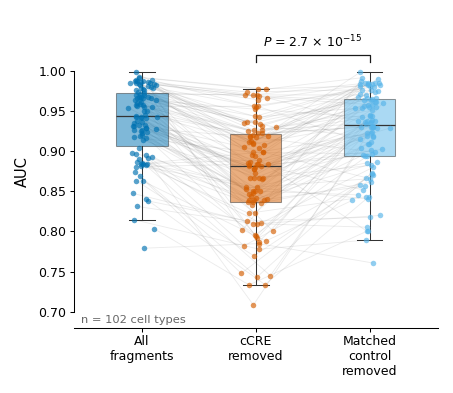

In [3]:
# ── Figure ─────────────────────────────────────────────────────────────────────
with plt.rc_context(PANEL_RC):
    fig, ax = plt.subplots(figsize=(3.0, 2.6))
    rng = np.random.default_rng(42)
    jit = rng.normal(0, 0.06, size=(len(df), len(CONDITIONS)))
    xs = np.arange(len(CONDITIONS)) + jit            # one x per point, shared by its line

    # Lines join each cell type's own points, so they meet the dots they belong to.
    for i in range(len(df)):
        ax.plot(xs[i], df.iloc[i][cols].to_numpy(float), color="#777777",
                alpha=0.15, lw=0.4, zorder=1)
    for k, (col, _, color) in enumerate(CONDITIONS):
        ax.boxplot([df[col]], positions=[k], widths=0.45, patch_artist=True,
                   boxprops=dict(facecolor=color, alpha=0.5, edgecolor="#333333", linewidth=0.5),
                   medianprops=dict(color="#333333", linewidth=0.6),
                   whiskerprops=dict(color="#333333", linewidth=0.5),
                   capprops=dict(color="#333333", linewidth=0.5),
                   flierprops=dict(marker="none"), zorder=2)
        ax.scatter(xs[:, k], df[col], s=7, color=color, alpha=0.65, linewidth=0,
                   zorder=3, rasterized=True)

    yb = 1.02
    ax.plot([1, 1, 2, 2], [yb - 0.008, yb, yb, yb - 0.008], color=INK, lw=0.6)
    ax.text(1.5, yb + 0.006, fmt_p(t.pvalue), ha="center", va="bottom", fontsize=6)

    ax.set_xticks(range(len(CONDITIONS)))
    ax.set_xticklabels([lab for _, lab, _ in CONDITIONS])
    ax.set_ylabel("AUC")
    yticks = np.round(np.arange(0.70, 1.001, 0.05), 2)
    ax.set_yticks(yticks)
    ax.set_ylim(0.68, 1.07)
    ax.set_xlim(-0.6, 2.6)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines["left"].set_bounds(yticks[0], yticks[-1])   # no AUC tick above 1
    ax.tick_params(axis="both", length=2, pad=1.5, width=0.5)
    ax.text(0.02, 0.01, f"n = {len(df)} cell types", transform=ax.transAxes,
            fontsize=5.5, color=MUTED, ha="left", va="bottom")
    fig.tight_layout()

    savefig(fig, OUT, "scatac_ccre_fragment_ablation",
            data=df.assign(paired_ttest_p_no_ccre_vs_matched=t.pvalue,
                           wilcoxon_p_no_ccre_vs_matched=w.pvalue))
    plt.show()

In [4]:
# ── Numbers for the figure legend ─────────────────────────────────────────────
print(f"mean AUC: all {df.auc_all_mean.mean():.3f}, cCRE removed {df.auc_no_ccre_mean.mean():.3f}, "
      f"matched control removed {df.auc_matched_mean.mean():.3f}")
print(f"mean drop: cCRE {df.drop_no_ccre.mean():.3f}, matched {df.drop_matched.mean():.3f}, "
      f"excess {df.excess_drop_vs_matched.mean():.3f}")
print(f"cCRE removal costs more than the matched control in "
      f"{int((df.excess_drop_vs_matched > 0).sum())}/{len(df)} cell types")
print(f"paired t-test  t = {t.statistic:.2f}, P = {t.pvalue:.2e}")
print(f"paired Wilcoxon signed-rank  P = {w.pvalue:.2e}")

mean AUC: all 0.935, cCRE removed 0.873, matched control removed 0.923
mean drop: cCRE 0.062, matched 0.013, excess 0.049
cCRE removal costs more than the matched control in 87/102 cell types
paired t-test  t = -9.33, P = 2.74e-15
paired Wilcoxon signed-rank  P = 1.01e-13
